<a href="https://colab.research.google.com/github/sakethk0507-pixel/Hallucination-Detection-and-Reliability-Scoring-for-LLM-Outputs-using-Transformer-Feature-Fusion/blob/main/Hallucination_Detection_Transformer_Feature_Fusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q transformers sentence-transformers scikit-learn pandas numpy matplotlib tqdm joblib gradio

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [ ]:
import os
import re
import random
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from tqdm.auto import tqdm

from sentence_transformers import SentenceTransformer

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    brier_score_loss
)

from sklearn.isotonic import IsotonicRegression

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", DEVICE)

In [ ]:
DATA_URL = "https://raw.githubusercontent.com/RUCAIBox/HaluEval/main/data/qa_data.json"

raw_df = pd.read_json(DATA_URL, lines=True)

print("Dataset shape:", raw_df.shape)
raw_df.head()
#data set importing

In [ ]:
print(raw_df.columns.tolist())

In [ ]:
print(raw_df.isnull().sum())

In [ ]:
MAX_PAIRS = 3000

if len(raw_df) > MAX_PAIRS:
    raw_df = raw_df.sample(
        n=MAX_PAIRS,
        random_state=SEED
    ).reset_index(drop=True)

print("Number of question pairs:", len(raw_df))

In [ ]:
raw_df["pair_id"] = np.arange(len(raw_df))

raw_df[[
    "pair_id",
    "question",
    "right_answer",
    "hallucinated_answer"
]].head()

In [ ]:
train_pairs, temp_pairs = train_test_split(
    raw_df["pair_id"],
    test_size=0.30,
    random_state=SEED
)

val_pairs, test_pairs = train_test_split(
    temp_pairs,
    test_size=0.50,
    random_state=SEED
)

print("Train pairs:", len(train_pairs))
print("Validation pairs:", len(val_pairs))
print("Test pairs:", len(test_pairs))

In [ ]:
def create_examples(df, pair_ids):

    subset = df[df["pair_id"].isin(pair_ids)]

    examples = []

    for _, row in subset.iterrows():

        # Correct/non-hallucinated answer
        examples.append({
            "pair_id": row["pair_id"],
            "knowledge": row["knowledge"],
            "question": row["question"],
            "answer": row["right_answer"],
            "label": 0
        })

        # Hallucinated answer
        examples.append({
            "pair_id": row["pair_id"],
            "knowledge": row["knowledge"],
            "question": row["question"],
            "answer": row["hallucinated_answer"],
            "label": 1
        })

    return pd.DataFrame(examples)

In [ ]:
train_df = create_examples(raw_df, train_pairs)
val_df = create_examples(raw_df, val_pairs)
test_df = create_examples(raw_df, test_pairs)

print("Training examples:", len(train_df))
print("Validation examples:", len(val_df))
print("Testing examples:", len(test_df))

In [ ]:
print("Training distribution:")
print(train_df["label"].value_counts())

print("\nValidation distribution:")
print(val_df["label"].value_counts())

print("\nTesting distribution:")
print(test_df["label"].value_counts())

In [ ]:
semantic_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2",
    device=str(DEVICE)
)

print("Semantic model loaded.")

In [ ]:
NLI_MODEL_NAME = "cross-encoder/nli-deberta-v3-small"

nli_tokenizer = AutoTokenizer.from_pretrained(
    NLI_MODEL_NAME
)

nli_model = AutoModelForSequenceClassification.from_pretrained(
    NLI_MODEL_NAME
)

nli_model = nli_model.to(DEVICE)
nli_model.eval()

print("NLI model loaded.")

In [ ]:
def extract_semantic_features(df, batch_size=64):

    contexts = [
        f"Question: {q} Evidence: {k}"
        for q, k in zip(
            df["question"],
            df["knowledge"]
        )
    ]

    answers = df["answer"].tolist()

    context_embeddings = semantic_model.encode(
        contexts,
        batch_size=batch_size,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    answer_embeddings = semantic_model.encode(
        answers,
        batch_size=batch_size,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    absolute_difference = np.abs(
        context_embeddings - answer_embeddings
    )

    elementwise_product = (
        context_embeddings * answer_embeddings
    )

    semantic_features = np.concatenate(
        [
            context_embeddings,
            answer_embeddings,
            absolute_difference,
            elementwise_product
        ],
        axis=1
    )

    return semantic_features

In [ ]:
def extract_nli_features(df, batch_size=16):

    all_probabilities = []

    knowledge_list = df["knowledge"].tolist()
    answer_list = df["answer"].tolist()

    for start in tqdm(
        range(0, len(df), batch_size),
        desc="Extracting NLI features"
    ):

        batch_knowledge = knowledge_list[
            start:start + batch_size
        ]

        batch_answers = answer_list[
            start:start + batch_size
        ]

        encoded = nli_tokenizer(
            batch_knowledge,
            batch_answers,
            padding=True,
            truncation=True,
            max_length=384,
            return_tensors="pt"
        )

        encoded = {
            key: value.to(DEVICE)
            for key, value in encoded.items()
        }

        with torch.no_grad():

            outputs = nli_model(**encoded)

            probabilities = torch.softmax(
                outputs.logits,
                dim=1
            )

        all_probabilities.append(
            probabilities.cpu().numpy()
        )

    return np.vstack(all_probabilities)

In [ ]:
def tokenize_simple(text):

    text = str(text).lower()

    return re.findall(
        r"\b[a-zA-Z0-9]+\b",
        text
    )

In [ ]:
def extract_lexical_features(df):

    features = []

    for _, row in df.iterrows():

        knowledge = str(row["knowledge"])
        question = str(row["question"])
        answer = str(row["answer"])

        knowledge_tokens = set(
            tokenize_simple(knowledge)
        )

        question_tokens = set(
            tokenize_simple(question)
        )

        answer_tokens_list = tokenize_simple(answer)
        answer_tokens = set(answer_tokens_list)

        # Jaccard overlap with evidence
        union = knowledge_tokens | answer_tokens

        if len(union) == 0:
            evidence_jaccard = 0
        else:
            evidence_jaccard = (
                len(knowledge_tokens & answer_tokens)
                / len(union)
            )

        # Fraction of answer words appearing in evidence
        if len(answer_tokens) == 0:
            evidence_coverage = 0
        else:
            evidence_coverage = (
                len(answer_tokens & knowledge_tokens)
                / len(answer_tokens)
            )

        # Question-answer overlap
        if len(answer_tokens) == 0:
            question_overlap = 0
        else:
            question_overlap = (
                len(answer_tokens & question_tokens)
                / len(answer_tokens)
            )

        # Answer length
        answer_length = len(answer_tokens_list)

        # Number consistency
        knowledge_numbers = set(
            re.findall(r"\d+(?:\.\d+)?", knowledge)
        )

        answer_numbers = set(
            re.findall(r"\d+(?:\.\d+)?", answer)
        )

        if len(answer_numbers) == 0:
            unsupported_number_ratio = 0.0
        else:
            unsupported = (
                answer_numbers - knowledge_numbers
            )

            unsupported_number_ratio = (
                len(unsupported)
                / len(answer_numbers)
            )

        features.append([
            evidence_jaccard,
            evidence_coverage,
            question_overlap,
            answer_length,
            unsupported_number_ratio
        ])

    return np.array(
        features,
        dtype=np.float32
    )

In [ ]:
print("Extracting semantic features for training data...")

train_semantic = extract_semantic_features(
    train_df
)

In [ ]:
print("Extracting NLI features for training data...")

train_nli = extract_nli_features(
    train_df
)

In [ ]:
train_lexical = extract_lexical_features(
    train_df
)

In [ ]:
print("Semantic:", train_semantic.shape)
print("NLI:", train_nli.shape)
print("Lexical:", train_lexical.shape)

Semantic: (4200, 1536)
NLI: (4200, 3)
Lexical: (4200, 5)


In [ ]:
val_semantic = extract_semantic_features(
    val_df
)

val_nli = extract_nli_features(
    val_df
)

val_lexical = extract_lexical_features(
    val_df
)

Batches:   0%|          | 0/15 [00:00<?, ?it/s]

Batches:   0%|          | 0/15 [00:00<?, ?it/s]

Extracting NLI features:   0%|          | 0/57 [00:00<?, ?it/s]

In [ ]:
test_semantic = extract_semantic_features(
    test_df
)

test_nli = extract_nli_features(
    test_df
)

test_lexical = extract_lexical_features(
    test_df
)

Batches:   0%|          | 0/15 [00:00<?, ?it/s]

Batches:   0%|          | 0/15 [00:00<?, ?it/s]

Extracting NLI features:   0%|          | 0/57 [00:00<?, ?it/s]

In [ ]:
X_train = np.concatenate(
    [
        train_semantic,
        train_nli,
        train_lexical
    ],
    axis=1
)

X_val = np.concatenate(
    [
        val_semantic,
        val_nli,
        val_lexical
    ],
    axis=1
)

X_test = np.concatenate(
    [
        test_semantic,
        test_nli,
        test_lexical
    ],
    axis=1
)

In [ ]:
y_train = train_df["label"].values
y_val = val_df["label"].values
y_test = test_df["label"].values

In [ ]:
print("Training feature matrix:", X_train.shape)
print("Validation feature matrix:", X_val.shape)
print("Testing feature matrix:", X_test.shape)

print("Feature dimension:", X_train.shape[1])

Training feature matrix: (4200, 1544)
Validation feature matrix: (900, 1544)
Testing feature matrix: (900, 1544)
Feature dimension: 1544


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)

X_test_scaled = scaler.transform(X_test)

In [ ]:
class HallucinationDataset(Dataset):

    def __init__(self, X, y):

        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )

        self.y = torch.tensor(
            y,
            dtype=torch.float32
        )

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):

        return (
            self.X[index],
            self.y[index]
        )

In [ ]:
train_dataset = HallucinationDataset(
    X_train_scaled,
    y_train
)

val_dataset = HallucinationDataset(
    X_val_scaled,
    y_val
)

test_dataset = HallucinationDataset(
    X_test_scaled,
    y_test
)

In [ ]:
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [ ]:
class FeatureFusionClassifier(nn.Module):

    def __init__(self, input_dim):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_dim, 512),

            nn.BatchNorm1d(512),

            nn.ReLU(),

            nn.Dropout(0.30),

            nn.Linear(512, 128),

            nn.ReLU(),

            nn.Dropout(0.20),

            nn.Linear(128, 32),

            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):

        return self.network(x).squeeze(1)

In [ ]:
model = FeatureFusionClassifier(
    input_dim=X_train_scaled.shape[1]
)

model = model.to(DEVICE)

print(model)

FeatureFusionClassifier(
  (network): Sequential(
    (0): Linear(in_features=1544, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=512, out_features=128, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.2, inplace=False)
    (7): Linear(in_features=128, out_features=32, bias=True)
    (8): ReLU()
    (9): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [ ]:
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

In [ ]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

In [ ]:
def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion
):

    model.train()

    running_loss = 0

    for X_batch, y_batch in loader:

        X_batch = X_batch.to(DEVICE)
        y_batch = y_batch.to(DEVICE)

        optimizer.zero_grad()

        logits = model(X_batch)

        loss = criterion(
            logits,
            y_batch
        )

        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item() * X_batch.size(0)
        )

    return (
        running_loss
        / len(loader.dataset)
    )

In [ ]:
def evaluate_loader(
    model,
    loader,
    criterion
):

    model.eval()

    running_loss = 0

    all_probabilities = []
    all_labels = []

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            logits = model(X_batch)

            loss = criterion(
                logits,
                y_batch
            )

            probabilities = torch.sigmoid(
                logits
            )

            running_loss += (
                loss.item()
                * X_batch.size(0)
            )

            all_probabilities.extend(
                probabilities.cpu().numpy()
            )

            all_labels.extend(
                y_batch.cpu().numpy()
            )

    average_loss = (
        running_loss
        / len(loader.dataset)
    )

    return (
        average_loss,
        np.array(all_labels),
        np.array(all_probabilities)
    )

In [ ]:
EPOCHS = 15

best_val_loss = float("inf")

history = {
    "train_loss": [],
    "val_loss": [],
    "val_f1": []
}

for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion
    )

    val_loss, val_labels, val_probs = evaluate_loader(
        model,
        val_loader,
        criterion
    )

    val_predictions = (
        val_probs >= 0.5
    ).astype(int)

    val_f1 = f1_score(
        val_labels,
        val_predictions
    )

    scheduler.step(val_loss)

    history["train_loss"].append(
        train_loss
    )

    history["val_loss"].append(
        val_loss
    )

    history["val_f1"].append(
        val_f1
    )

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val F1: {val_f1:.4f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            "best_hallucination_model.pt"
        )

Epoch 01 | Train Loss: 0.2462 | Val Loss: 0.1200 | Val F1: 0.9552
Epoch 02 | Train Loss: 0.0886 | Val Loss: 0.1107 | Val F1: 0.9655
Epoch 03 | Train Loss: 0.0489 | Val Loss: 0.1111 | Val F1: 0.9632
Epoch 04 | Train Loss: 0.0283 | Val Loss: 0.1523 | Val F1: 0.9612
Epoch 05 | Train Loss: 0.0280 | Val Loss: 0.1305 | Val F1: 0.9630
Epoch 06 | Train Loss: 0.0106 | Val Loss: 0.1416 | Val F1: 0.9696
Epoch 07 | Train Loss: 0.0039 | Val Loss: 0.1538 | Val F1: 0.9675
Epoch 08 | Train Loss: 0.0019 | Val Loss: 0.1811 | Val F1: 0.9694
Epoch 09 | Train Loss: 0.0031 | Val Loss: 0.1754 | Val F1: 0.9682
Epoch 10 | Train Loss: 0.0031 | Val Loss: 0.1750 | Val F1: 0.9684
Epoch 11 | Train Loss: 0.0040 | Val Loss: 0.1767 | Val F1: 0.9694
Epoch 12 | Train Loss: 0.0032 | Val Loss: 0.1783 | Val F1: 0.9662
Epoch 13 | Train Loss: 0.0023 | Val Loss: 0.1795 | Val F1: 0.9683
Epoch 14 | Train Loss: 0.0012 | Val Loss: 0.1823 | Val F1: 0.9706
Epoch 15 | Train Loss: 0.0013 | Val Loss: 0.1786 | Val F1: 0.9707


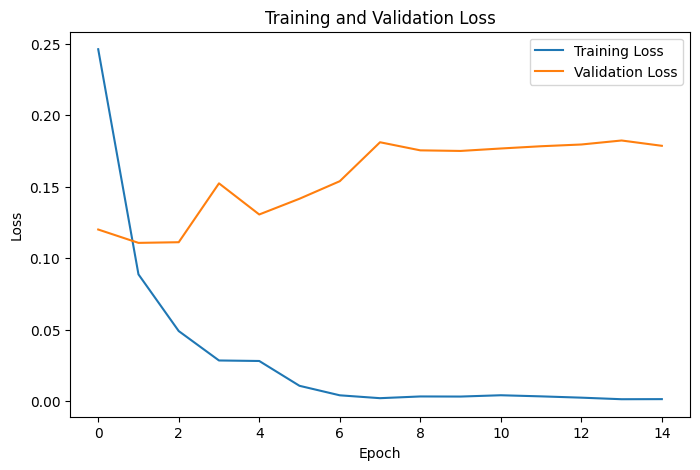

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.show()

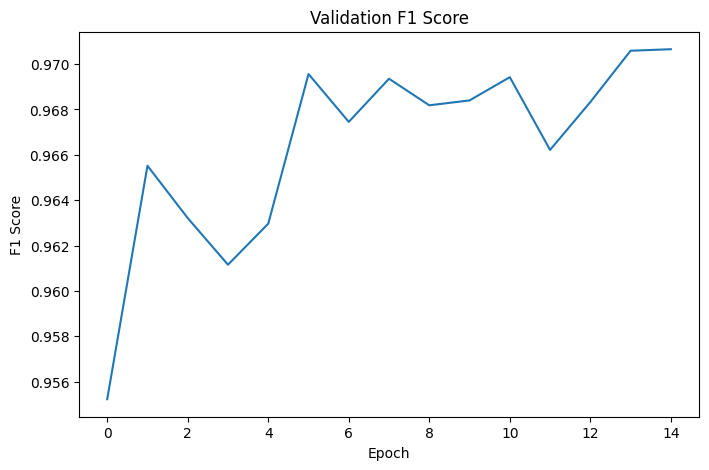

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history["val_f1"]
)

plt.xlabel("Epoch")
plt.ylabel("F1 Score")
plt.title("Validation F1 Score")

plt.show()

In [ ]:
model.load_state_dict(
    torch.load(
        "best_hallucination_model.pt",
        map_location=DEVICE
    )
)

model.eval()

FeatureFusionClassifier(
  (network): Sequential(
    (0): Linear(in_features=1544, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=512, out_features=128, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.2, inplace=False)
    (7): Linear(in_features=128, out_features=32, bias=True)
    (8): ReLU()
    (9): Linear(in_features=32, out_features=1, bias=True)
  )
)

In [ ]:
_, val_labels, val_probs = evaluate_loader(
    model,
    val_loader,
    criterion
)

thresholds = np.arange(
    0.20,
    0.81,
    0.01
)

best_threshold = 0.5
best_f1 = 0

for threshold in thresholds:

    predictions = (
        val_probs >= threshold
    ).astype(int)

    score = f1_score(
        val_labels,
        predictions
    )

    if score > best_f1:

        best_f1 = score
        best_threshold = threshold

print(
    "Best threshold:",
    best_threshold
)

print(
    "Validation F1:",
    best_f1
)

Best threshold: 0.5400000000000003
Validation F1: 0.96875


In [ ]:
calibrator = IsotonicRegression(
    out_of_bounds="clip"
)

calibrator.fit(
    val_probs,
    val_labels
)

IsotonicRegression(out_of_bounds='clip')

In [ ]:
test_loss, test_labels, test_raw_probs = evaluate_loader(
    model,
    test_loader,
    criterion
)

In [ ]:
test_probs = calibrator.predict(
    test_raw_probs
)

In [ ]:
test_predictions = (
    test_probs >= best_threshold
).astype(int)

In [ ]:
accuracy = accuracy_score(
    test_labels,
    test_predictions
)

precision = precision_score(
    test_labels,
    test_predictions
)

recall = recall_score(
    test_labels,
    test_predictions
)

f1 = f1_score(
    test_labels,
    test_predictions
)

roc_auc = roc_auc_score(
    test_labels,
    test_probs
)

brier = brier_score_loss(
    test_labels,
    test_probs
)

print("TEST RESULTS")
print("-" * 40)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")
print(f"Brier     : {brier:.4f}")

TEST RESULTS
----------------------------------------
Accuracy  : 0.9589
Precision : 0.9704
Recall    : 0.9467
F1 Score  : 0.9584
ROC-AUC   : 0.9906
Brier     : 0.0325


In [ ]:
print(
    classification_report(
        test_labels,
        test_predictions,
        target_names=[
            "Reliable",
            "Hallucinated"
        ]
    )
)

              precision    recall  f1-score   support

    Reliable       0.95      0.97      0.96       450
Hallucinated       0.97      0.95      0.96       450

    accuracy                           0.96       900
   macro avg       0.96      0.96      0.96       900
weighted avg       0.96      0.96      0.96       900



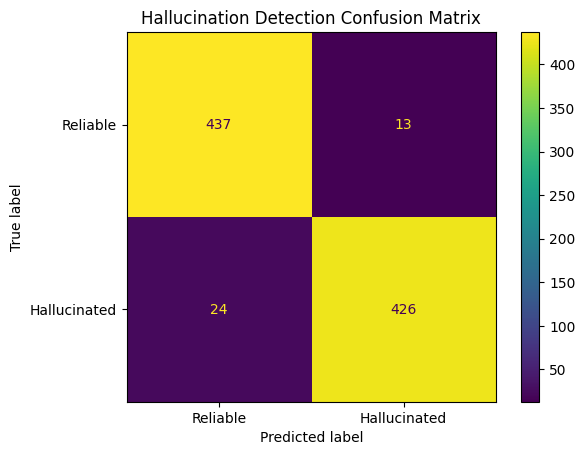

In [ ]:
cm = confusion_matrix(
    test_labels,
    test_predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Reliable",
        "Hallucinated"
    ]
)

disp.plot()

plt.title(
    "Hallucination Detection Confusion Matrix"
)

plt.show()

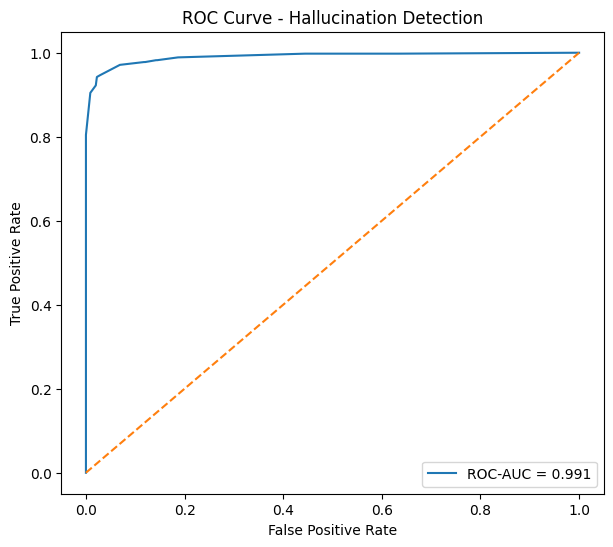

In [ ]:
fpr, tpr, thresholds = roc_curve(
    test_labels,
    test_probs
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {roc_auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve - Hallucination Detection"
)

plt.legend()

plt.show()

In [ ]:
def probability_to_reliability(
    hallucination_probability
):

    reliability = (
        1.0
        - hallucination_probability
    ) * 100

    return float(
        np.clip(
            reliability,
            0,
            100
        )
    )

In [ ]:
def reliability_level(score):

    if score >= 80:
        return "High Reliability"

    elif score >= 60:
        return "Moderate Reliability"

    elif score >= 40:
        return "Low Reliability"

    else:
        return "Very Low Reliability"

In [ ]:
def extract_single_features(
    knowledge,
    question,
    answer
):

    temp_df = pd.DataFrame({
        "knowledge": [knowledge],
        "question": [question],
        "answer": [answer]
    })

    semantic = extract_semantic_features(
        temp_df,
        batch_size=1
    )

    nli = extract_nli_features(
        temp_df,
        batch_size=1
    )

    lexical = extract_lexical_features(
        temp_df
    )

    features = np.concatenate(
        [
            semantic,
            nli,
            lexical
        ],
        axis=1
    )

    features_scaled = scaler.transform(
        features
    )

    return features_scaled

In [ ]:
def detect_hallucination_v2(
    knowledge,
    question,
    answer
):

    # -------------------------
    # 1. Original fusion model
    # -------------------------

    features = extract_single_features(
        knowledge,
        question,
        answer
    )

    features_tensor = torch.tensor(
        features,
        dtype=torch.float32
    ).to(DEVICE)

    model.eval()

    with torch.no_grad():

        logit = model(
            features_tensor
        )

        mlp_hallucination_prob = torch.sigmoid(
            logit
        ).item()

    # -------------------------
    # 2. NLI signal
    # -------------------------

    encoded = nli_tokenizer(
        knowledge,
        answer,
        padding=True,
        truncation=True,
        max_length=384,
        return_tensors="pt"
    )

    encoded = {
        k: v.to(DEVICE)
        for k, v in encoded.items()
    }

    nli_model.eval()

    with torch.no_grad():

        outputs = nli_model(
            **encoded
        )

        probs = torch.softmax(
            outputs.logits,
            dim=-1
        )[0].cpu().numpy()

    contradiction = float(probs[0])
    entailment = float(probs[1])
    neutral = float(probs[2])

    # -------------------------
    # 3. Combine probabilities
    # -------------------------
    # Strong NLI-aware fusion
    # Strong NLI-aware fusion

    if entailment >= 0.90 and contradiction <= 0.10:
        final_hallucination_prob = (
            0.10 * mlp_hallucination_prob
            +
            0.90 * (1 - entailment)
        )

    elif contradiction >= 0.90:
        final_hallucination_prob = (
            0.10 * mlp_hallucination_prob
            +
            0.90 * contradiction
        )

    else:
        nli_hallucination_prob = (
            contradiction
            + 0.5 * neutral
        )

        final_hallucination_prob = (
            0.30 * mlp_hallucination_prob
            +
            0.70 * nli_hallucination_prob
        )

    final_hallucination_prob = float(
        np.clip(
            final_hallucination_prob,
            0,
            1
        )
    )


    reliability_score = (
        1 - final_hallucination_prob
    ) * 100

    # -------------------------
    # 4. Final decision
    # -------------------------

    if final_hallucination_prob >= 0.5:

        prediction = "Hallucinated"

    else:

        prediction = "Reliable / Supported"

    if reliability_score >= 80:

        level = "High Reliability"

    elif reliability_score >= 60:

        level = "Moderate Reliability"

    elif reliability_score >= 40:

        level = "Low Reliability"

    else:

        level = "Very Low Reliability"

    return {

        "Prediction": prediction,

        "Hallucination Probability":
            round(
                final_hallucination_prob,
                4
            ),

        "Reliability Score":
            round(
                reliability_score,
                2
            ),

        "Reliability Level":
            level,

        "MLP Probability":
            round(
                mlp_hallucination_prob,
                4
            ),

        "Entailment":
            round(
                entailment,
                4
            ),

        "Contradiction":
            round(
                contradiction,
                4
            ),

        "Neutral":
            round(
                neutral,
                4
            )
    }

In [ ]:
result = detect_hallucination_v2(
    knowledge="""
Water freezes at 0 degrees Celsius under standard atmospheric pressure
and boils at 100 degrees Celsius.
""",

    question="""
At what temperature does water freeze and boil?
""",

    answer="""
Water freezes at 0 degrees Celsius and boils at 100 degrees Celsius
under standard atmospheric pressure.
"""
)

print(result)

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Extracting NLI features:   0%|          | 0/1 [00:00<?, ?it/s]

{'Prediction': 'Reliable / Supported', 'Hallucination Probability': 0.1015, 'Reliability Score': 89.85, 'Reliability Level': 'High Reliability', 'MLP Probability': 0.9255, 'Entailment': 0.9901, 'Contradiction': 0.0018, 'Neutral': 0.0081}


In [ ]:
result = detect_hallucination_v2(
    knowledge="""
Water freezes at 0 degrees Celsius under standard atmospheric pressure
and boils at 100 degrees Celsius.
""",

    question="""
At what temperature does water freeze and boil?
""",

    answer="""
Water freezes at 50 degrees Celsius and boils at 200 degrees Celsius.
"""
)

print(result)

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Extracting NLI features:   0%|          | 0/1 [00:00<?, ?it/s]

{'Prediction': 'Hallucinated', 'Hallucination Probability': 0.9987, 'Reliability Score': 0.13, 'Reliability Level': 'Very Low Reliability', 'MLP Probability': 0.9946, 'Entailment': 0.0001, 'Contradiction': 0.9991, 'Neutral': 0.0008}


In [ ]:
sample = raw_df.iloc[0]

print("QUESTION:")
print(sample["question"])

print("\nKNOWLEDGE:")
print(sample["knowledge"])

print("\nCORRECT ANSWER:")
print(sample["right_answer"])

print("\nHALLUCINATED ANSWER:")
print(sample["hallucinated_answer"])

QUESTION:
The manager in which Mark Lazarus clashed with served as manager for the Wolverhampton Wanderers during which years?

KNOWLEDGE:
 He transferred to Wolverhampton Wanderers for a club record fee, but due to a clash with manager Stan Cullis, he moved back to QPR after only nine games. During his term as manager between 1948 and 1964, Wolves became one of the strongest teams in the British game, winning the league title on three occasions, and playing a series of high-profile friendly matches against top European sides which acted as a precursor to the European Cup.

CORRECT ANSWER:
1948 and 1964

HALLUCINATED ANSWER:
Mark Lazarus clashed with the manager of Wolverhampton Wanderers during the years of 1950 and 1960.


In [ ]:
result_correct = detect_hallucination_v2(
    knowledge=sample["knowledge"],
    question=sample["question"],
    answer=sample["right_answer"]
)

print(result_correct)

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Extracting NLI features:   0%|          | 0/1 [00:00<?, ?it/s]

{'Prediction': 'Reliable / Supported', 'Hallucination Probability': 0.4223, 'Reliability Score': 57.77, 'Reliability Level': 'Low Reliability', 'MLP Probability': 0.2388, 'Entailment': 0.0005, 'Contradiction': 0.0023, 'Neutral': 0.9972}


In [ ]:
result_hallucinated = detect_hallucination_v2(
    knowledge=sample["knowledge"],
    question=sample["question"],
    answer=sample["hallucinated_answer"]
)

print(result_hallucinated)

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Extracting NLI features:   0%|          | 0/1 [00:00<?, ?it/s]

{'Prediction': 'Hallucinated', 'Hallucination Probability': 0.9479, 'Reliability Score': 5.21, 'Reliability Level': 'Very Low Reliability', 'MLP Probability': 0.9999, 'Entailment': 0.0042, 'Contradiction': 0.9422, 'Neutral': 0.0537}


In [ ]:
temp_df = pd.DataFrame({
    "knowledge": [sample["knowledge"]],
    "question": [sample["question"]],
    "answer": [sample["hallucinated_answer"]]
})

nli_values = extract_nli_features(
    temp_df,
    batch_size=1
)

print(nli_values)

Extracting NLI features:   0%|          | 0/1 [00:00<?, ?it/s]

[[0.94215393 0.00416035 0.05368572]]


In [ ]:
print(
    "Contradiction:",
    nli_values[0][0]
)

print(
    "Entailment:",
    nli_values[0][1]
)

print(
    "Neutral:",
    nli_values[0][2]
)

Contradiction: 0.94215393
Entailment: 0.0041603465
Neutral: 0.053685717


In [ ]:
reliability_scores = (
    1 - test_probs
) * 100

In [ ]:
reliable_scores = reliability_scores[
    test_labels == 0
]

hallucinated_scores = reliability_scores[
    test_labels == 1
]

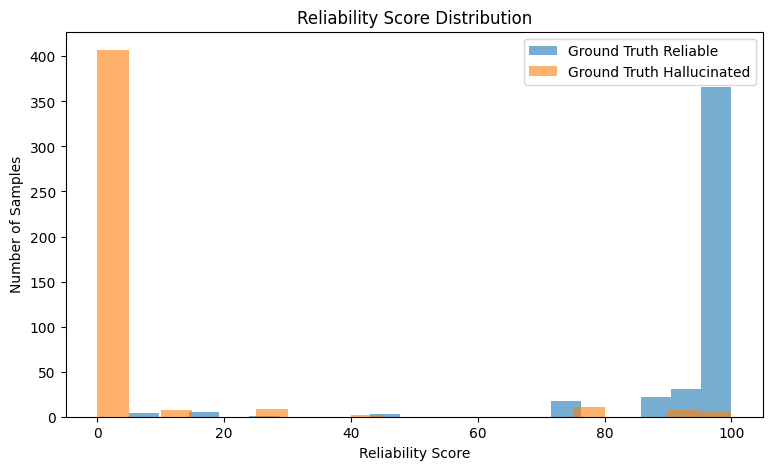

In [ ]:
plt.figure(figsize=(9, 5))

plt.hist(
    reliable_scores,
    bins=20,
    alpha=0.6,
    label="Ground Truth Reliable"
)

plt.hist(
    hallucinated_scores,
    bins=20,
    alpha=0.6,
    label="Ground Truth Hallucinated"
)

plt.xlabel("Reliability Score")
plt.ylabel("Number of Samples")

plt.title(
    "Reliability Score Distribution"
)

plt.legend()

plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
def evaluate_feature_set(
    train_features,
    test_features,
    name
):

    local_scaler = StandardScaler()

    train_scaled = local_scaler.fit_transform(
        train_features
    )

    test_scaled = local_scaler.transform(
        test_features
    )

    classifier = LogisticRegression(
        max_iter=2000,
        random_state=SEED
    )

    classifier.fit(
        train_scaled,
        y_train
    )

    probs = classifier.predict_proba(
        test_scaled
    )[:, 1]

    preds = (
        probs >= 0.5
    ).astype(int)

    return {
        "Model": name,

        "Accuracy": accuracy_score(
            y_test,
            preds
        ),

        "Precision": precision_score(
            y_test,
            preds
        ),

        "Recall": recall_score(
            y_test,
            preds
        ),

        "F1": f1_score(
            y_test,
            preds
        ),

        "ROC-AUC": roc_auc_score(
            y_test,
            probs
        )
    }

In [ ]:
ablation_results = []

ablation_results.append(
    evaluate_feature_set(
        train_semantic,
        test_semantic,
        "MiniLM only"
    )
)

ablation_results.append(
    evaluate_feature_set(
        train_nli,
        test_nli,
        "DeBERTa NLI only"
    )
)

ablation_results.append(
    evaluate_feature_set(
        np.concatenate(
            [train_semantic, train_nli],
            axis=1
        ),
        np.concatenate(
            [test_semantic, test_nli],
            axis=1
        ),
        "MiniLM + NLI"
    )
)

ablation_results.append(
    evaluate_feature_set(
        X_train,
        X_test,
        "Full Feature Fusion"
    )
)

ablation_df = pd.DataFrame(
    ablation_results
)

ablation_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,MiniLM only,0.932222,0.935123,0.928889,0.931996,0.970904
1,DeBERTa NLI only,0.703333,0.680473,0.766667,0.721003,0.714607
2,MiniLM + NLI,0.935556,0.943439,0.926667,0.934978,0.977136
3,Full Feature Fusion,0.961111,0.974828,0.946667,0.960541,0.994277


In [ ]:
torch.save(
    {
        "model_state_dict":
            model.state_dict(),

        "input_dim":
            X_train_scaled.shape[1],

        "best_threshold":
            float(best_threshold)
    },

    "hallucination_detector.pt"
)

In [ ]:
joblib.dump(
    scaler,
    "feature_scaler.pkl"
)

['feature_scaler.pkl']

In [ ]:
joblib.dump(
    calibrator,
    "probability_calibrator.pkl"
)

['probability_calibrator.pkl']

In [ ]:
results = {
    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1": float(f1),
    "roc_auc": float(roc_auc),
    "brier_score": float(brier),
    "threshold": float(best_threshold)
}

with open(
    "evaluation_results.json",
    "w"
) as f:

    json.dump(
        results,
        f,
        indent=4
    )

In [ ]:
ablation_df.to_csv(
    "ablation_results.csv",
    index=False
)

In [ ]:
def debug_prediction(
    knowledge,
    question,
    answer
):

    features = extract_single_features(
        knowledge,
        question,
        answer
    )

    features_tensor = torch.tensor(
        features,
        dtype=torch.float32
    ).to(DEVICE)

    model.eval()

    with torch.no_grad():

        logit = model(
            features_tensor
        )

        raw_probability = torch.sigmoid(
            logit
        ).item()

    calibrated_probability = float(
        calibrator.predict(
            [raw_probability]
        )[0]
    )

    print("Raw hallucination probability:",
          raw_probability)

    print("Calibrated hallucination probability:",
          calibrated_probability)

    print("Reliability before calibration:",
          (1 - raw_probability) * 100)

    print("Reliability after calibration:",
          (1 - calibrated_probability) * 100)

In [ ]:
debug_prediction(
    knowledge="""
Water freezes at 0 degrees Celsius under standard atmospheric pressure
and boils at 100 degrees Celsius.
""",

    question="""
At what temperature does water freeze and boil?
""",

    answer="""
Water freezes at 0 degrees Celsius and boils at 100 degrees Celsius
under standard atmospheric pressure.
"""
)

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Extracting NLI features:   0%|          | 0/1 [00:00<?, ?it/s]

Raw hallucination probability: 0.9255484938621521
Calibrated hallucination probability: 0.9508196711540222
Reliability before calibration: 7.44515061378479
Reliability after calibration: 4.918032884597778


In [ ]:
import gradio as gr

In [ ]:
def gradio_predict(
    evidence,
    question,
    llm_answer
):

    if (
        not evidence.strip()
        or not question.strip()
        or not llm_answer.strip()
    ):

        return (
            "Please provide evidence, "
            "a question, and an LLM answer."
        )

    result = detect_hallucination_v2(
        knowledge=evidence,
        question=question,
        answer=llm_answer
    )

    output = f"""
## Hallucination Analysis

**Prediction:** {result['Prediction']}

**Hallucination Probability:** {result['Hallucination Probability']}

**Reliability Score:** {result['Reliability Score']} / 100

**Reliability Level:** {result['Reliability Level']}

---

### Model Signals

**MLP Probability:** {result['MLP Probability']}

**Entailment:** {result['Entailment']}

**Contradiction:** {result['Contradiction']}

**Neutral:** {result['Neutral']}
"""

    return output

In [ ]:
demo = gr.Interface(

    fn=gradio_predict,

    inputs=[
        gr.Textbox(
            lines=8,
            label="Supporting Evidence / Context"
        ),

        gr.Textbox(
            lines=3,
            label="Question"
        ),

        gr.Textbox(
            lines=5,
            label="LLM Generated Answer"
        )
    ],

    outputs=gr.Textbox(
        label="Hallucination Analysis"
    ),

    title=(
        "Hallucination Detection and "
        "Reliability Scoring"
    ),

    description=(
        "Transformer Feature Fusion using "
        "MiniLM semantic representations "
        "and DeBERTa NLI signals."
    )
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4f4344eccaf35a9d85.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
